# Chapter 6: Advanced Logistic Regression and Extensions

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup

## Learning Objectives

After completing this chapter, we will be able to:

1. Understand and implement logistic regression.
2. Perform multiclass classification.
3. Apply regularization to logistic regression.
4. Understand multilabel classification.
5. Evaluate classification models using appropriate metrics.

## Table of Contents

1. Overview of Logistic Regression
2. Multiclass Classification Techniques
3. Regularization in Logistic Regression
4. Multilabel Classification Concepts
5. Model Evaluation Metrics
6. Practical Exercises
7. Summary

## Technical Requirements

This chapter uses Python and several data science libraries:

- NumPy for numerical operations.
- pandas for organizing data.
- Matplotlib and Seaborn for visualization.
- scikit-learn for datasets, model training, and evaluation.

The examples use datasets available directly from scikit-learn, so we do not need to download separate dataset files.

The code is intended to run in Google Colab or a local Jupyter Notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Overview of Logistic Regression

Logistic regression is a supervised machine learning algorithm commonly used for classification tasks.

Although its name contains the word "regression," it is often used to predict categories, such as whether a tumor is malignant or benign.

The model estimates the probability that an observation belongs to a particular class. For binary classification, it commonly uses the logistic or sigmoid function to convert a numerical score into a probability between 0 and 1.

### Important Concepts

- **Training data:** Data used to learn the model parameters.
- **Testing data:** Data used to evaluate the model on unseen examples.
- **Prediction:** The class estimated by the trained model.
- **Probability:** The estimated likelihood of belonging to a class.
- **Accuracy:** The proportion of predictions that are correct.

In this example, we use the Breast Cancer dataset provided by scikit-learn.

In [2]:
# Load the Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Convert the features into a DataFrame
df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nTarget classes:")
print(data.target_names)

print("\nClass distribution:")
print(df["target"].value_counts())

Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target classes:
['malignant' 'benign']

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2024,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [4]:
# Create and train the model
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



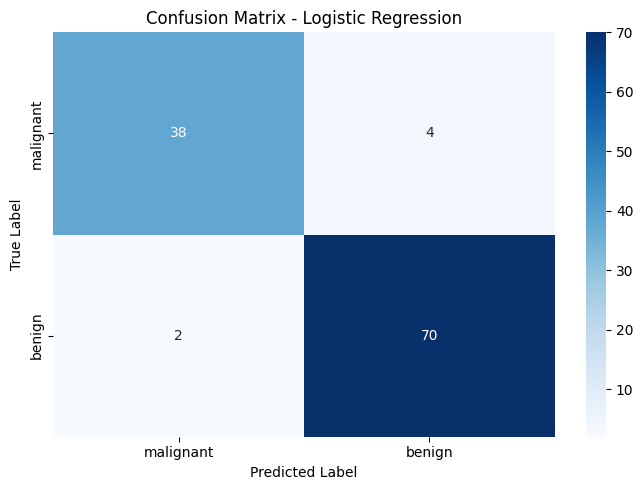

In [5]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

### How It Works

The model learns relationships between the input features and the target classes during training.

After training, `predict()` estimates the class for each test observation. The accuracy score measures the proportion of correct predictions.

The confusion matrix provides additional information by showing how many observations were classified correctly and incorrectly for each class.

The classification report provides precision, recall, and F1-score for a more detailed evaluation.

The exact results may differ if the dataset split, preprocessing, or model settings are changed.

## 2. Multiclass Classification Techniques

Multiclass classification is used when a classification problem has more than two possible classes.

For example, the Iris dataset contains three flower species:

- Setosa
- Versicolor
- Virginica

Two common approaches to multiclass logistic regression are:

### One-vs-Rest (OvR)

One-vs-Rest trains a binary classifier for each class. Each classifier distinguishes one class from all remaining classes.

### Multinomial Logistic Regression

Multinomial logistic regression models the probabilities of multiple mutually exclusive classes together, commonly using the softmax function.

The two approaches can be compared using the same dataset and testing split.

In [6]:
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = (
    train_test_split(
        X_iris,
        y_iris,
        test_size=0.3,
        random_state=2024,
        stratify=y_iris
    )
)

print("Feature names:", iris.feature_names)
print("Class names:", iris.target_names)
print("Training samples:", len(X_train_iris))
print("Testing samples:", len(X_test_iris))

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']
Training samples: 105
Testing samples: 45


In [7]:
# One-vs-Rest model
ovr_model = LogisticRegression(
    solver="liblinear",
    max_iter=1000
)

ovr_model.fit(X_train_iris, y_train_iris)
y_pred_ovr = ovr_model.predict(X_test_iris)

# Multinomial model
multinomial_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

multinomial_model.fit(X_train_iris, y_train_iris)
y_pred_multinomial = multinomial_model.predict(X_test_iris)

# Compare accuracy
accuracy_ovr = accuracy_score(y_test_iris, y_pred_ovr)
accuracy_multinomial = accuracy_score(
    y_test_iris,
    y_pred_multinomial
)

print(f"OvR Accuracy: {accuracy_ovr:.4f}")
print(f"Multinomial Accuracy: {accuracy_multinomial:.4f}")

OvR Accuracy: 0.9778
Multinomial Accuracy: 0.9333


In [8]:
print("One-vs-Rest Classification Report")
print(
    classification_report(
        y_test_iris,
        y_pred_ovr,
        target_names=iris.target_names
    )
)

print("\nMultinomial Classification Report")
print(
    classification_report(
        y_test_iris,
        y_pred_multinomial,
        target_names=iris.target_names
    )
)

One-vs-Rest Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45


Multinomial Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



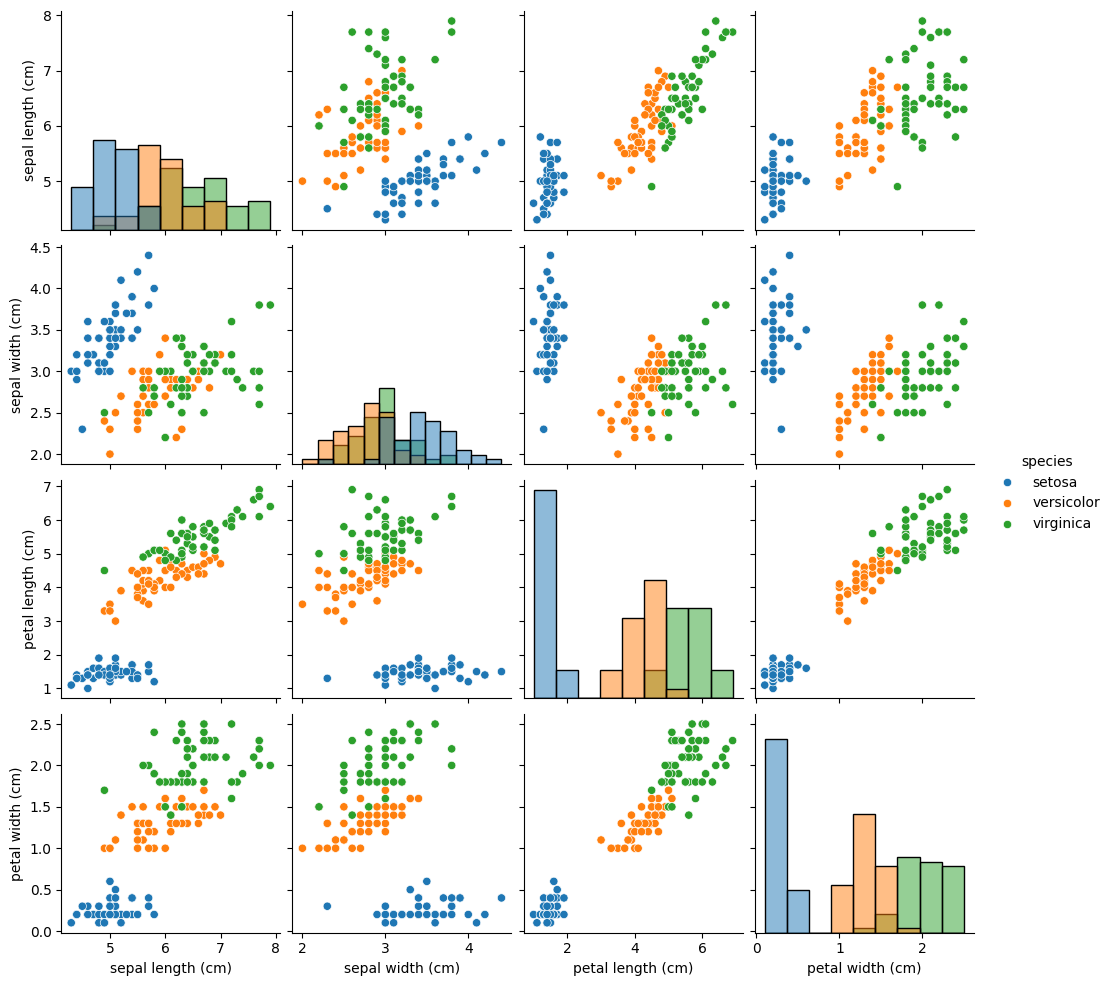

In [9]:
iris_df = pd.DataFrame(
    X_iris,
    columns=iris.feature_names
)

iris_df["species"] = [
    iris.target_names[label] for label in y_iris
]

sns.pairplot(
    iris_df,
    hue="species",
    diag_kind="hist"
)

plt.show()

### How It Works

The Iris dataset has three target classes, so the model must distinguish between more than two categories.

OvR handles the problem by training separate binary classifiers. Multinomial logistic regression instead estimates the class probabilities together.

The accuracy scores and classification reports show how each approach performs on the same testing data.

The pairplot displays relationships between flower measurements. It helps us observe which features may separate the species.

A higher accuracy score does not automatically mean that one method is better for every dataset. Model performance depends on the data, preprocessing, and evaluation method.

## 3. Regularization in Logistic Regression

Regularization is a technique used to reduce overfitting by penalizing excessively large model coefficients.

Two common types of regularization are:

### L1 Regularization (Lasso)

L1 regularization penalizes the absolute values of the coefficients. It can reduce some coefficients to exactly zero, which may help with feature selection.

### L2 Regularization (Ridge)

L2 regularization penalizes the squared values of the coefficients. It generally shrinks coefficients toward zero without forcing most of them to become exactly zero.

In scikit-learn's LogisticRegression, the parameter `C` represents the inverse of regularization strength:

- A smaller `C` means stronger regularization.
- A larger `C` means weaker regularization.

Feature scaling is useful when the input features have different numerical scales.

In [10]:
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=2024,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (398, 30)
Testing data: (171, 30)


In [11]:
# L2 regularization
ridge_model = LogisticRegression(
    penalty="l2",
    solver="liblinear",
    C=0.1,
    max_iter=5000
)

ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

# L1 regularization
lasso_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.1,
    max_iter=5000
)

lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

print(
    "L2 Accuracy:",
    round(accuracy_score(y_test, y_pred_ridge), 4)
)

print(
    "L1 Accuracy:",
    round(accuracy_score(y_test, y_pred_lasso), 4)
)

print("\nNumber of nonzero L2 coefficients:",
      np.count_nonzero(ridge_model.coef_))

print("Number of nonzero L1 coefficients:",
      np.count_nonzero(lasso_model.coef_))

L2 Accuracy: 0.9825
L1 Accuracy: 0.9649

Number of nonzero L2 coefficients: 30
Number of nonzero L1 coefficients: 8


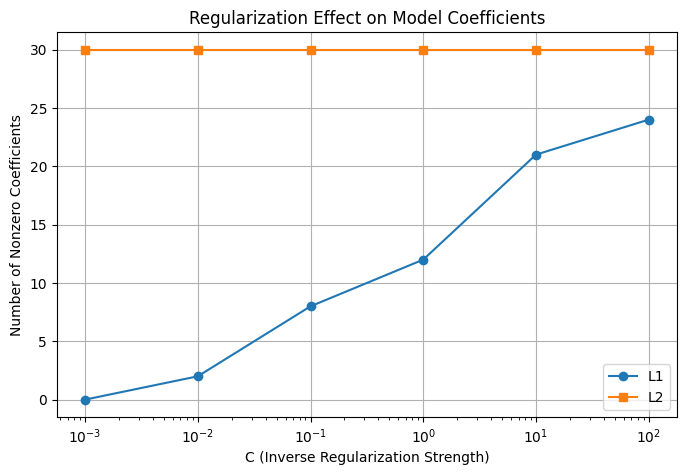

In [12]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

l1_nonzero = []
l2_nonzero = []

for c_value in C_values:
    model_l1 = LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=c_value,
        max_iter=5000
    )
    model_l2 = LogisticRegression(
        penalty="l2",
        solver="liblinear",
        C=c_value,
        max_iter=5000
    )

    model_l1.fit(X_train_scaled, y_train)
    model_l2.fit(X_train_scaled, y_train)

    l1_nonzero.append(np.count_nonzero(model_l1.coef_))
    l2_nonzero.append(np.count_nonzero(model_l2.coef_))

plt.figure(figsize=(8, 5))

plt.plot(C_values, l1_nonzero, marker="o", label="L1")
plt.plot(C_values, l2_nonzero, marker="s", label="L2")

plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Number of Nonzero Coefficients")
plt.title("Regularization Effect on Model Coefficients")
plt.legend()
plt.grid(True)
plt.show()

### How It Works

The two models use the same training and testing data, allowing their results to be compared.

The L1 model may eliminate some features by assigning their coefficients a value of zero. The L2 model generally shrinks coefficient values without eliminating as many features.

The graph shows how the number of nonzero coefficients changes as `C` changes.

Regularization does not guarantee higher accuracy in every experiment. Its purpose is to help control model complexity and improve generalization to unseen data.

## 4. Multilabel Classification Concepts

Multilabel classification is different from ordinary multiclass classification.

In multiclass classification, each observation typically belongs to one class. In multilabel classification, one observation may have several labels at the same time.

For example, a document could be labeled as both "technology" and "education."

To demonstrate this, we will generate a synthetic dataset with multiple binary labels for each observation.

We will then train a separate logistic regression classifier for each label using the One-vs-Rest approach.

In [13]:
from sklearn.datasets import make_multilabel_classification

X_multi, y_multi = make_multilabel_classification(
    n_samples=1000,
    n_features=20,
    n_classes=5,
    n_labels=2,
    random_state=2024
)

print("Feature shape:", X_multi.shape)
print("Label shape:", y_multi.shape)

print("\nFirst five label combinations:")
print(y_multi[:5])

Feature shape: (1000, 20)
Label shape: (1000, 5)

First five label combinations:
[[0 1 0 0 0]
 [0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [1 1 0 0 1]]


In [14]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = (
    train_test_split(
        X_multi,
        y_multi,
        test_size=0.3,
        random_state=2024
    )
)

models = []
predictions = []

for i in range(y_train_multi.shape[1]):
    model = LogisticRegression(
        solver="liblinear",
        max_iter=1000
    )

    model.fit(X_train_multi, y_train_multi[:, i])

    y_pred_label = model.predict(X_test_multi)

    models.append(model)
    predictions.append(y_pred_label)

y_pred_multi = np.array(predictions).T

print("Actual labels shape:", y_test_multi.shape)
print("Predicted labels shape:", y_pred_multi.shape)

Actual labels shape: (300, 5)
Predicted labels shape: (300, 5)


In [15]:
from sklearn.metrics import hamming_loss

subset_accuracy = accuracy_score(
    y_test_multi,
    y_pred_multi
)

print(f"Subset Accuracy: {subset_accuracy:.4f}")
print(f"Hamming Loss: {hamming_loss(y_test_multi, y_pred_multi):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_multi,
        y_pred_multi,
        zero_division=0
    )
)

Subset Accuracy: 0.3400
Hamming Loss: 0.2087

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       166
           1       0.80      0.85      0.82       181
           2       0.67      0.33      0.45        93
           3       0.75      0.18      0.29        34
           4       0.58      0.48      0.52        88

   micro avg       0.76      0.65      0.70       562
   macro avg       0.72      0.53      0.58       562
weighted avg       0.74      0.65      0.68       562
 samples avg       0.72      0.61      0.62       562



In [ ]:
### How It Works

The generated target matrix contains several binary labels for each observation.

The code trains one binary logistic regression model per label. The predictions from all models are combined into one matrix.

Subset accuracy measures the proportion of observations for which every predicted label matches the true label. It is therefore a strict metric for multilabel tasks.

Hamming loss measures the proportion of incorrectly predicted label entries. A lower value indicates fewer individual label errors.

The classification report provides precision, recall, and F1-score for each label.

## 5. Model Evaluation Metrics

Evaluating a classification model requires more than looking at its predictions.

Important metrics include:

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** The proportion of positive predictions that are correct.
- **Recall:** The proportion of actual positive cases that are correctly identified.
- **F1-score:** The harmonic mean of precision and recall.
- **ROC curve:** Shows the trade-off between the true positive rate and false positive rate at different thresholds.
- **AUC:** Measures the area under the ROC curve.

The most suitable metric depends on the problem. For example, recall may be especially important when missing a positive case has serious consequences.

In [16]:
# Train a binary classifier
evaluation_model = LogisticRegression(
    solver="liblinear",
    max_iter=5000
)

evaluation_model.fit(X_train_scaled, y_train)

y_pred_eval = evaluation_model.predict(X_test_scaled)
y_prob_eval = evaluation_model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred_eval)
precision = precision_score(y_test, y_pred_eval, zero_division=0)
recall = recall_score(y_test, y_pred_eval, zero_division=0)
f1 = f1_score(y_test, y_pred_eval, zero_division=0)

fpr, tpr, thresholds = roc_curve(y_test, y_prob_eval)
roc_auc = auc(fpr, tpr)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

Accuracy:  0.9708
Precision: 0.9722
Recall:    0.9813
F1-score:  0.9767
ROC AUC:   0.9946


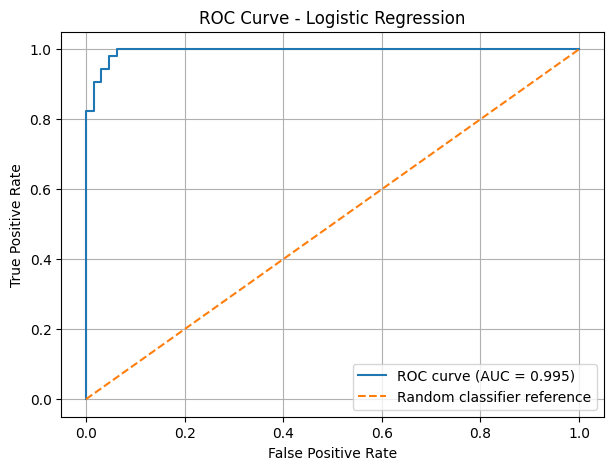

In [17]:
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.95      0.96        64
      benign       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



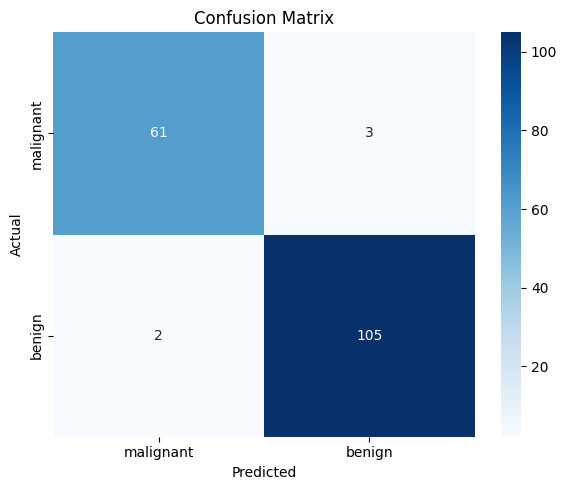

In [18]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_eval,
        target_names=cancer.target_names
    )
)

cm = confusion_matrix(y_test, y_pred_eval)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### How It Works

Accuracy provides an overall measure of correct predictions. However, it does not explain which kinds of errors the model makes.

Precision and recall provide more specific information about positive predictions and actual positive cases.

The F1-score combines precision and recall into a single metric. The ROC curve shows model performance across different probability thresholds, while AUC summarizes the curve into one value.

The confusion matrix helps identify the number of correct and incorrect predictions for each class.

These metrics should be interpreted together and in the context of the classification problem.

In [19]:
exercise_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.1,
    max_iter=5000
)

exercise_model.fit(X_train_scaled, y_train)

exercise_pred = exercise_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, exercise_pred))
print(
    classification_report(
        y_test,
        exercise_pred,
        target_names=cancer.target_names
    )
)

Accuracy: 0.9649122807017544
              precision    recall  f1-score   support

   malignant       0.94      0.97      0.95        64
      benign       0.98      0.96      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.97      0.96       171
weighted avg       0.97      0.96      0.97       171



In [20]:
exercise_multi_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

exercise_multi_model.fit(X_train_iris, y_train_iris)

exercise_multi_pred = exercise_multi_model.predict(X_test_iris)

print(
    "Multiclass Accuracy:",
    accuracy_score(y_test_iris, exercise_multi_pred)
)

print(
    classification_report(
        y_test_iris,
        exercise_multi_pred,
        target_names=iris.target_names
    )
)

Multiclass Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



Synthetic Dataset Accuracy: 0.95


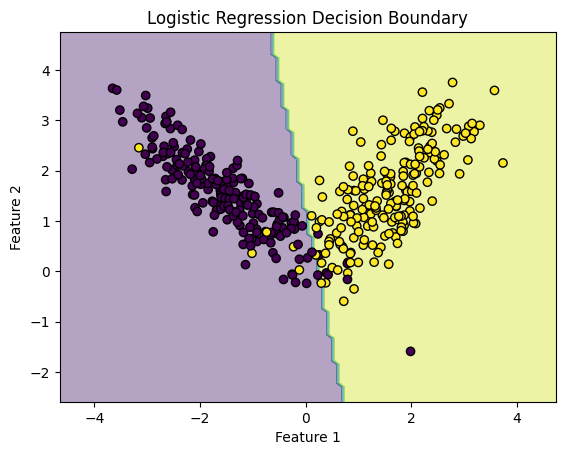

In [21]:
from sklearn.datasets import make_classification
from sklearn.inspection import DecisionBoundaryDisplay

X_synthetic, y_synthetic = make_classification(
    n_samples=400,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=2024
)

X_train_syn, X_test_syn, y_train_syn, y_test_syn = (
    train_test_split(
        X_synthetic,
        y_synthetic,
        test_size=0.3,
        random_state=2024,
        stratify=y_synthetic
    )
)

synthetic_model = LogisticRegression()
synthetic_model.fit(X_train_syn, y_train_syn)

print(
    "Synthetic Dataset Accuracy:",
    accuracy_score(
        y_test_syn,
        synthetic_model.predict(X_test_syn)
    )
)

DecisionBoundaryDisplay.from_estimator(
    synthetic_model,
    X_synthetic,
    response_method="predict",
    alpha=0.4
)

plt.scatter(
    X_synthetic[:, 0],
    X_synthetic[:, 1],
    c=y_synthetic,
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Decision Boundary")
plt.show()

## 7. Summary

This chapter explored advanced logistic regression techniques and their applications to classification problems.

The main concepts learned are:

1. **Logistic regression:** A supervised learning algorithm used to estimate class probabilities and make classification predictions.
2. **Multiclass classification:** One-vs-Rest and multinomial logistic regression are approaches for handling problems with more than two classes.
3. **Regularization:** L1 and L2 penalties help control model complexity and reduce overfitting.
4. **Multilabel classification:** A single observation can have multiple labels, and separate binary classifiers can be used to predict them.
5. **Model evaluation:** Accuracy, precision, recall, F1-score, ROC curves, AUC, and confusion matrices provide different perspectives on model performance.

The chapter also demonstrated how to load datasets, split data, train models, make predictions, evaluate results, and visualize classification behavior using Python and scikit-learn.

Overall, model selection and evaluation should be guided by the structure of the dataset and the objectives of the classification task.